# Edge elements and the tree-cotree gauge

This notebook follows `docs/tutorials/data/two_wires_3D_edge_el_2order`: two rods along z crossing a box, a source rod with an
imposed current density and a **solid** rod whose ends are shorted (V = 0 on both end faces), discretized with
**Nedelec edge elements** (`AV3D_edge`). It shows:

* why edge elements need a quadratic mesh (their DOFs live on the midside nodes) and how their Dirichlet values are
  written (component 2 of `_A` on the midside nodes: the tangential A along each edge);
* the tree-cotree gauge: what `tree_gauge()` builds from the current selection, and how to look at the tree;
* a static step followed by transient steps, and the eddy current induced in the shorted rod.

See the user manual (*Element Library: AV3D_edge*, *Boundary Conditions: gauging*).

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("data/two_wires_3D_edge_el_2order").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_two_wires_3D_edge_el_2order_"))
for name in ("two_wires_3D_edge_el_2order.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

working in a temporary folder: pytec3d_two_wires_3D_edge_el_2order_dem871zs


In [2]:
from pytec3d import tree_gauge
solver = Solver()
solver.read_model("two_wires_3D_edge_el_2order.vtu")
solver.model.read_json("model_data.json")
mesh = solver.model.mesh
midside = meshes.array_values(mesh, "MidsideNodes", "node") == 1
print(solver.model, f"- {midside.sum()} midside nodes (one edge DOF each)")
for k, row in solver.model.data["element_types"].items():
    print("TYPE", k, row)

Model('two_wires_3D_edge_el_2order', 5928 points, 1210 cells) - 4344 midside nodes (one edge DOF each)
TYPE 21 {'element_type': 2, 'option1': 0, 'option2': 2, 'option3': 0}
TYPE 23 {'element_type': 2, 'option1': 3, 'option2': 2, 'option3': 0}
TYPE 24 {'element_type': 2, 'option1': 5, 'option2': 2, 'option3': 0}


## Tangential A = 0 on the six faces, then the gauge

On each face of the box we keep the midside nodes of the selection and fix component 2 of `_A`: this fixes the
circulation of A along every edge of the face, i.e. n x A = 0. Then the gauge: `tree_gauge()` builds a spanning tree of
the edges of the **selected cells** (all of them), grown from the **selected nodes** (the external boundary, where A
is already fixed), and fixes A = 0 on the tree edges. The ends of the solid rod are shorted with V = 0.

In [3]:
for axis in (0, 1, 2):
    selection.select_pos(mesh, axis, (0.499, 0.50001))
    selection.select_pos(mesh, axis, (-0.501, -0.49999), mode="a")
    selection.select(mesh, "MidsideNodes", 1, mode="r")
    selection.set_value_on_selection(mesh, "_A", 0.0, 2)

for face in ("LOWER_FACE_ROD", "UPPER_FACE_ROD"):
    selection.select(mesh, face, 1)
    selection.set_value_on_selection(mesh, "_V", 0.0)

selection.select_all(mesh)
selection.nsel_ext(mesh)
info = tree_gauge.tree_gauge(mesh)
print({k: info[k] for k in ("num_edges", "num_tree", "num_cotree", "num_roots", "tree_identity_ok")})

{'num_edges': 4344, 'num_tree': 900, 'num_cotree': 3444, 'num_roots': 684, 'tree_identity_ok': True}


The tree is stored in the point array `TREE` (1 on the midside node of each tree edge). In a connected graph a
spanning tree has (number of nodes - number of roots) edges: the remaining (cotree) edges carry the solution.

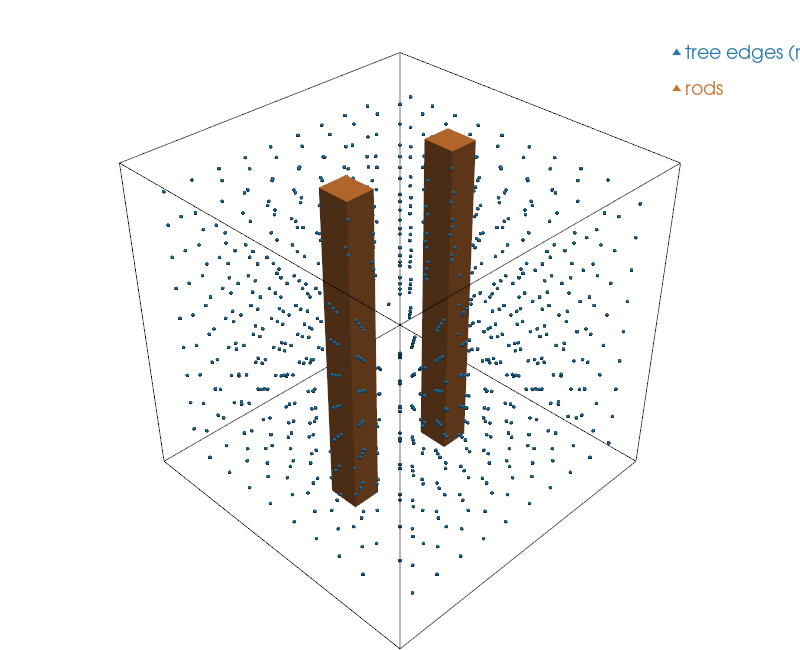

In [4]:
grid = pv.wrap(mesh).copy()
tree_points = pv.PolyData(grid.points[grid.point_data["TREE"] == 1])
rods = grid.threshold(value=(22, 30), scalars="TYPE")
pl = pv.Plotter(window_size=(800, 650))
pl.add_mesh(grid.outline(), color="black")
pl.add_mesh(tree_points, color="#2a7ab0", point_size=4, render_points_as_spheres=True, label="tree edges (midside nodes)")
pl.add_mesh(rods, color="#c87533", label="rods")
pl.add_legend(bcolor="white", size=(0.35, 0.12))
pl.camera_position = "iso"
pl.show()

## Steps: static, rise, switch-off

* step 1, static: Js = 1 A/m^2 in the source rod (no eddy currents on a static step);
* step 2, transient (dt = 1 ms): Js = 100 A/m^2, a sudden rise: the shorted rod reacts;
* step 3, transient: Js = 0, the source is switched off.

We use theta = 1 (backward Euler) for these steps: they are sudden changes of the source, and theta < 1 would carry
part of the rate before each change into the next step (see the remark at the end of section 8 of the first tutorial).

The current through the shorted rod is estimated from its element current density, `J_z * volume / length` summed
over its cells (the mean over its length).

In [5]:
with quietly():
    solver.load_model_into_solver()
cells = meshes.array_values(mesh, "MATERIAL", "elem")
volume = meshes.array_values(mesh, "cell_volume", "elem")
rod, source = cells == 24, cells == 23
length = 1.0                                            # the rods cross the box along z

def set_source(js):
    selection.select(mesh, "MATERIAL", 23, location="elem")
    selection.set_value_on_selection(mesh, "Js", js, 2, location="elem")

rows = []
for time, theta, transient, js in ((1e-3, 1.0, False, 1.0), (2e-3, 1.0, True, 100.0), (3e-3, 1.0, True, 0.0)):
    set_source(js)
    solver.time_step.update(time=time, theta=theta, transient_effects=transient)
    solver.solve()
    jz = meshes.array_values(mesh, "Jt", "elem")[:, 2]
    rows.append((time, js * np.sum(volume[source]) / length, np.sum(jz[rod] * volume[rod]) / length))
    print(f"t = {time:.0e} s ({'transient' if transient else 'static'}): source {rows[-1][1]:.3e} A, "
          f"shorted rod {rows[-1][2]: .3e} A, linear its {solver.steps[-1]['linear_iterations']}")
solver.write_output()

t = 1e-03 s (static): source 9.000e-03 A, shorted rod  0.000e+00 A, linear its 1
t = 2e-03 s (transient): source 9.000e-01 A, shorted rod -2.022e-01 A, linear its 1
t = 3e-03 s (transient): source 0.000e+00 A, shorted rod  2.171e-03 A, linear its 1


The flux density on the mid-plane z = 0, and the current density in the rods (last step: the source is off, the eddy
current of the shorted rod decays):

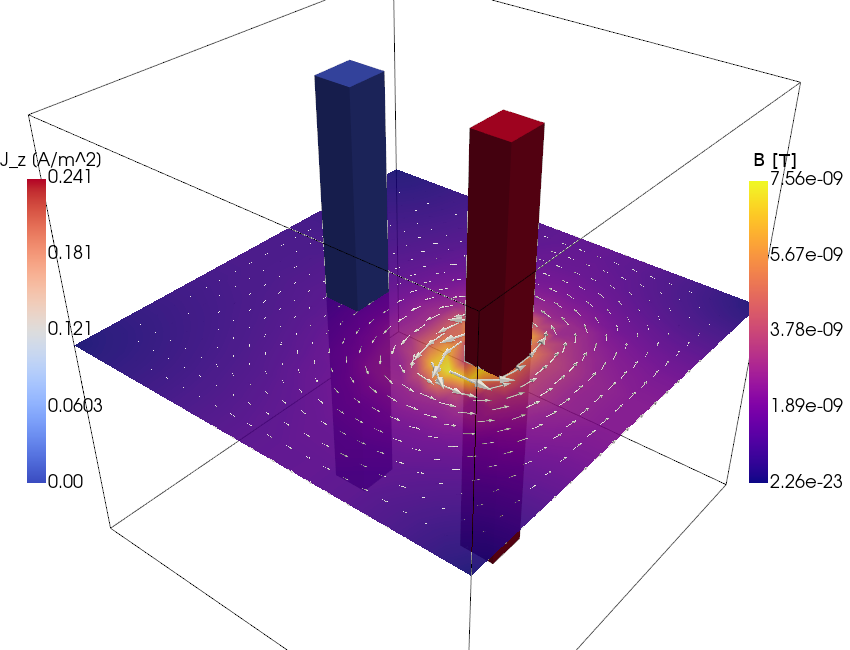

In [6]:
grid = pv.wrap(mesh).copy()
grid.point_data["|B|"] = np.linalg.norm(grid.point_data["B"], axis=1)
plane = grid.slice(normal="z", origin=(0, 0, 0))
rods = grid.threshold(value=(22, 30), scalars="TYPE")
# Jt: the imposed density Js in the source rod, the computed (eddy) current density in the shorted rod.
rods.cell_data["J_z"] = rods.cell_data["Jt"][:, 2]
arrows = plane.glyph(orient="B", scale="|B|", factor=0.1 / max(plane["|B|"].max(), 1e-30), tolerance=0.03)

pl = pv.Plotter(window_size=(850, 650))
pl.add_mesh(plane, scalars="|B|", cmap="plasma", opacity=0.9, scalar_bar_args={"title": "|B| [T]", "vertical": True, "position_x": 0.88, "position_y": 0.25, "height": 0.5, "width": 0.06})
pl.add_mesh(arrows, color="white")
pl.add_mesh(rods, scalars="J_z", cmap="coolwarm", scalar_bar_args={"title": "J_z [A/m^2]", "vertical": True, "position_x": 0.03, "position_y": 0.25, "height": 0.5, "width": 0.06})
pl.add_mesh(grid.outline(), color="black")
pl.camera_position = [(1.3, -1.6, 1.4), (0, 0, 0), (0, 0, 1)]
pl.show()
with quietly():
    solver.close()

## Try it yourself

* Call `tree_gauge()` with no cell selected (`selection.unselect_all(mesh)` first): the tree is empty (`num_tree = 0`)
  and the curl-curl matrix of the air is singular. Add `"-mat_mumps_icntl_24": "1"` to
  `solver.solver_settings["petsc_options"]` to see the null pivots in the step report.
* Leave the rod ends free (no `_V`): the rod is open, and no net current flows through it, only local eddy currents.